In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [6]:
train=pd.read_csv("/content/train.csv")
test=pd.read_csv("/content/test.csv")
sample_submission=pd.read_csv("/content/submission.csv")

In [7]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Submission template shape:", sample_submission.shape)
display(train.head())
display(test.head())
display(sample_submission.head())

Train shape: (18076, 12)
Test shape: (4520, 11)
Submission template shape: (4520, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left
0,18395,Southwest,WN 2981,San Francisco,Morning,zero,Afternoon,San Diego,Economy,1.67,32
1,11771,Southwest,WN 2526,Los Angeles,Night,zero,Night,San Jose,Economy,1.17,19
2,22326,Alaska_Airlines,AS 3359,San Jose,Morning,one,Evening,Sacramento,Business,6.13,44
3,18332,Southwest,WN 2462,San Jose,Afternoon,zero,Afternoon,Los Angeles,Economy,1.33,26
4,11021,American_Airlines,AA 6279,Sacramento,Morning,one,Afternoon,San Francisco,Economy,3.87,19


,id,price
0,18395,18395
1,11771,11771
2,22326,22326
3,18332,18332
4,11021,11021


In [8]:
print("Training dtypes:")
display(train.dtypes.rename("dtype").to_frame())
print("\\nMissing values in train:")
display(train.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("\\nMissing values in test:")
display(test.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate IDs in train/test:", train["id"].duplicated().sum(), test["id"].duplicated().sum())

assert "price" in train.columns, "Target column 'price' was not found in train.csv"
assert "price" not in test.columns, "test.csv should not contain the target"
assert set(sample_submission.columns) == {"id", "price"}, "Check the expected submission columns"

Training dtypes:


,dtype
id,int64
airline,object
flight,object
source_city,object
departure_time,object
stops,object
arrival_time,object
destination_city,object
flight_class,object
duration,float64


\nMissing values in train:


,missing_count
id,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
flight_class,0
duration,0


\nMissing values in test:


,missing_count
id,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
flight_class,0
duration,0


Duplicate rows in train: 0
Duplicate IDs in train/test: 0 0


In [9]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,18076.0,NaN,NaN,NaN,11308.626189,6526.337957,0.0,5668.75,11329.5,16949.5,22595.0
airline,18076,7,Alaska_Airlines,4554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight,18076,1123,AA 6279,183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_city,18076,5,Los Angeles,4561,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_time,18076,6,Morning,5144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stops,18076,3,zero,13559,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_time,18076,6,Afternoon,4785,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_city,18076,5,Los Angeles,4533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_class,18076,2,Economy,10711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,18076.0,NaN,NaN,NaN,2.746853,2.947519,0.87,1.47,1.63,2.0,28.65


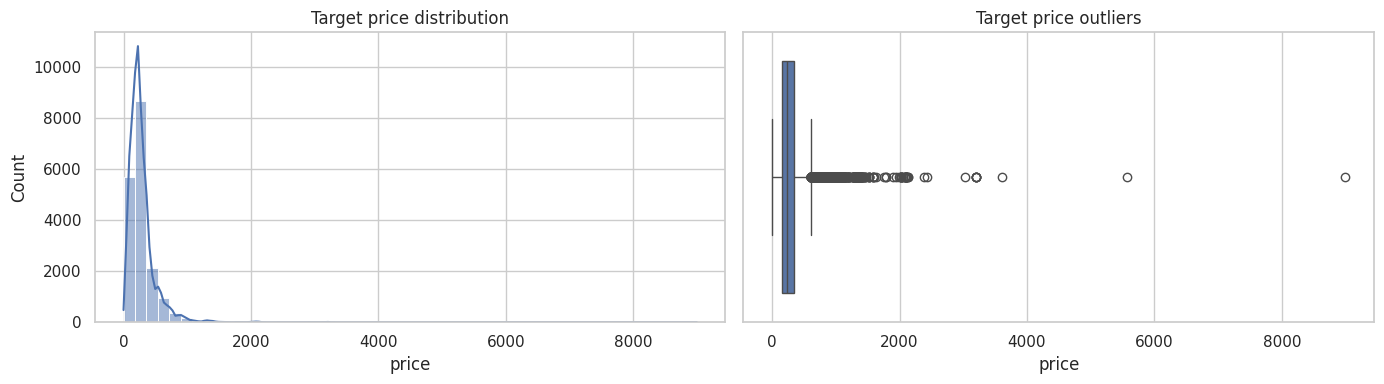

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train["price"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Target price distribution")
sns.boxplot(x=train["price"], ax=axes[1])
axes[1].set_title("Target price outliers")
plt.tight_layout()
plt.show()

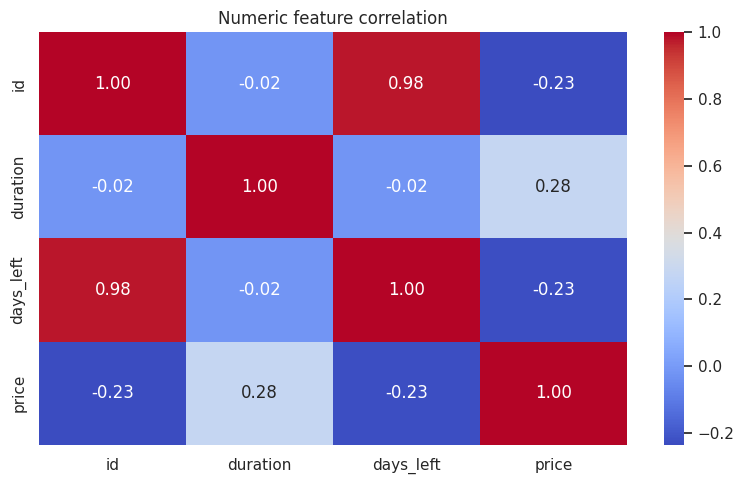

In [11]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
corr = train[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numeric feature correlation")
plt.tight_layout()
plt.show()

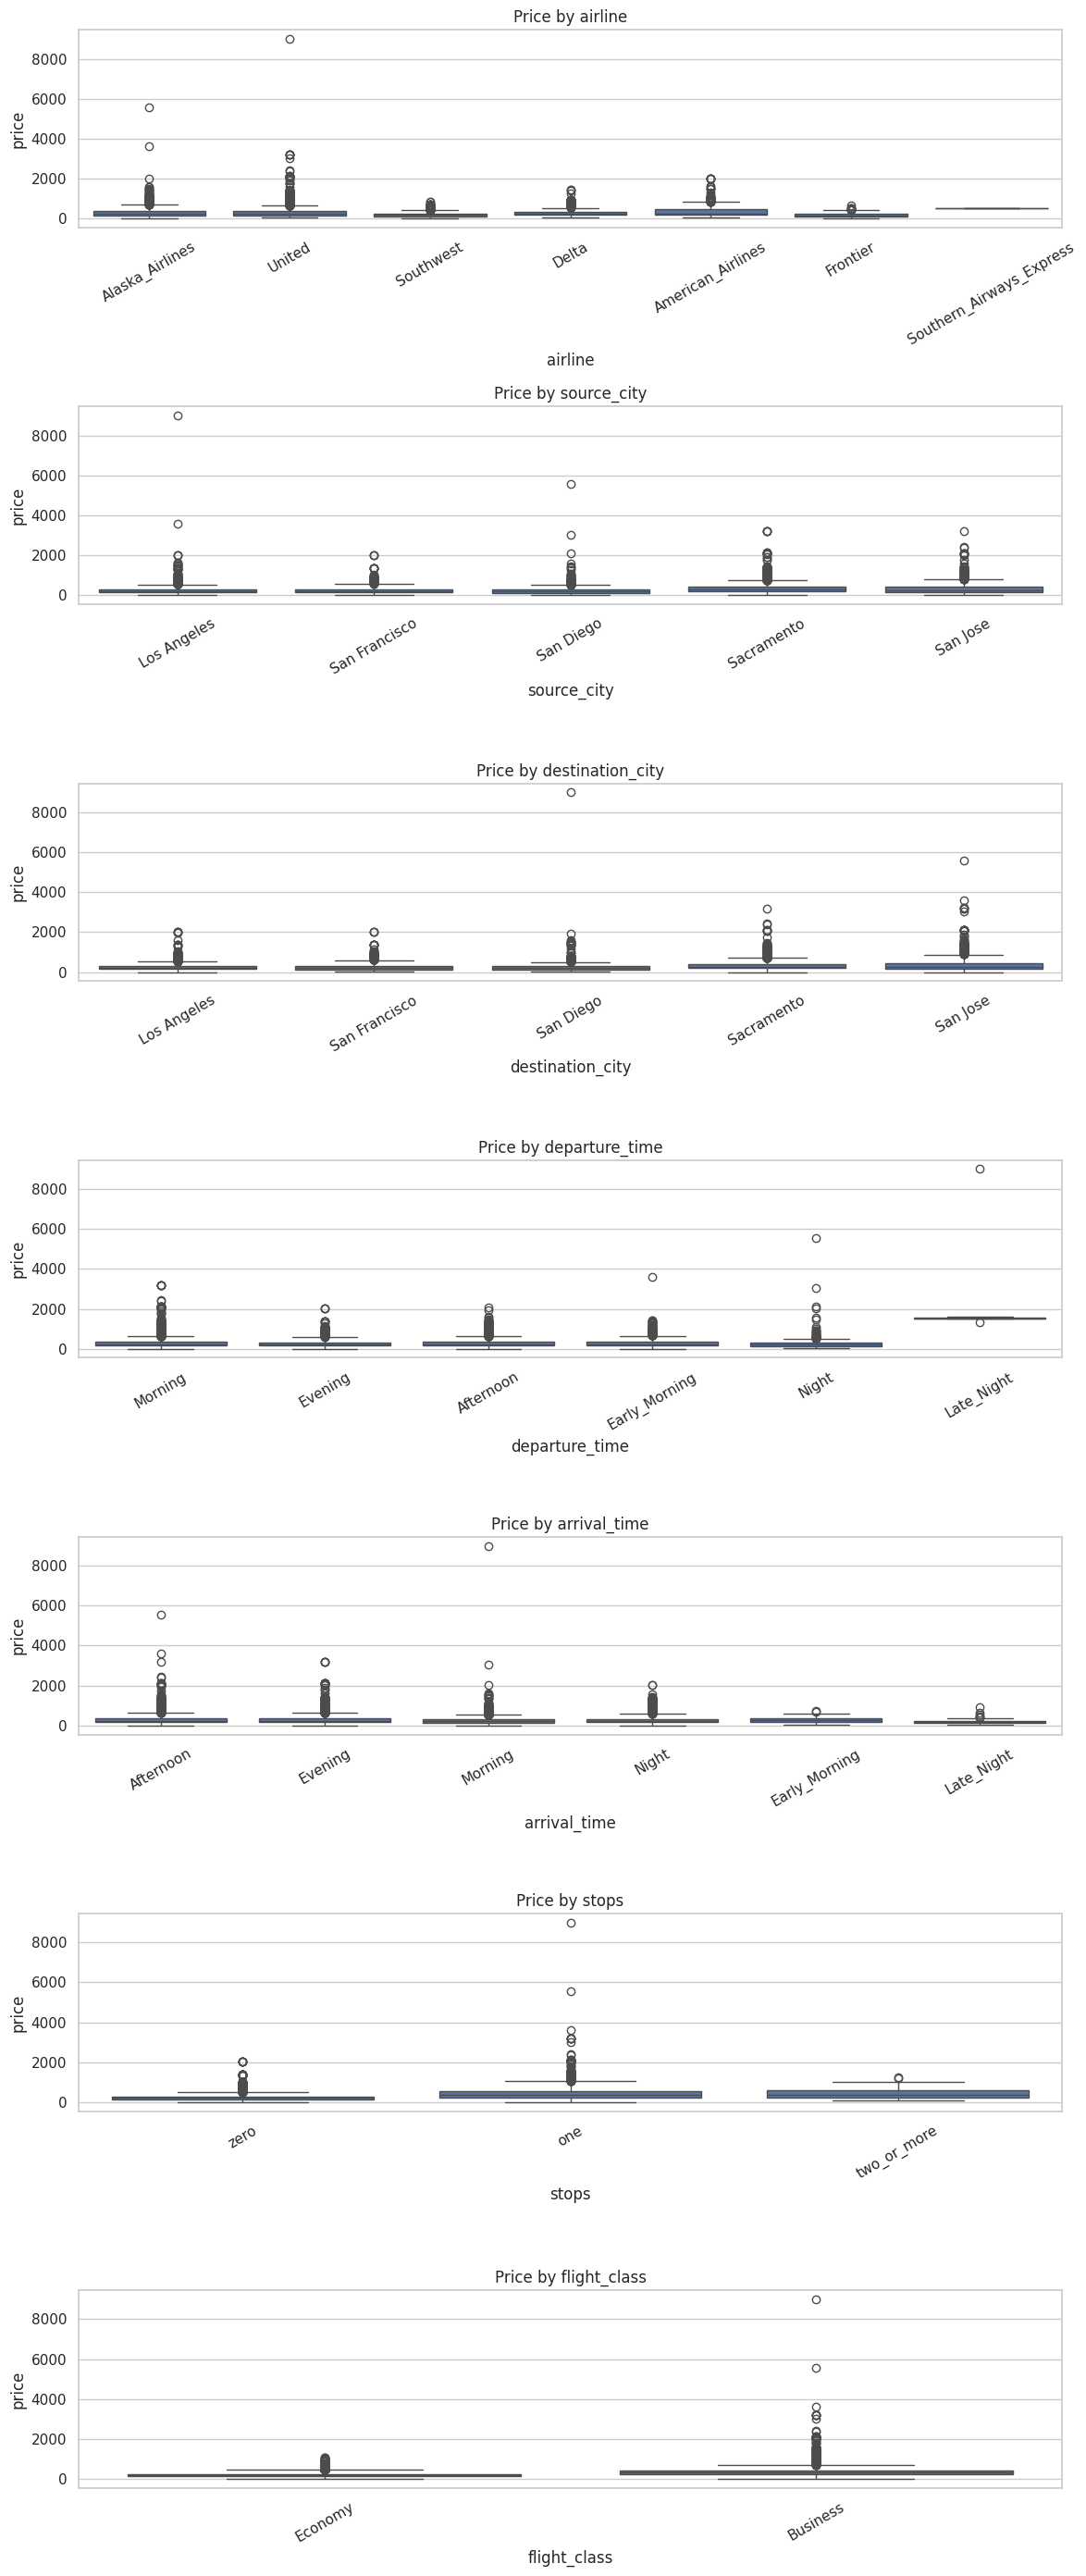

In [12]:
categorical_for_eda = [
    c for c in ["airline", "source_city", "destination_city", "departure_time",
                "arrival_time", "stops", "flight_class"] if c in train.columns
]
fig, axes = plt.subplots(len(categorical_for_eda), 1, figsize=(12, 4 * len(categorical_for_eda)))
if len(categorical_for_eda) == 1:
    axes = [axes]
for ax, col in zip(axes, categorical_for_eda):
    order = train[col].value_counts().index
    sns.boxplot(data=train, x=col, y="price", order=order, ax=ax)
    ax.set_title(f"Price by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [13]:
def make_features(df):
    df = df.copy()

    # Extract information from values such as 'WN 3596'.
    flight_parts = df["flight"].astype(str).str.extract(r"^\s*([A-Za-z]+)\s*(\d+)\s*$")
    df["flight_code_prefix"] = flight_parts[0].fillna("Unknown")
    df["flight_number"] = pd.to_numeric(flight_parts[1], errors="coerce")

    # Route may capture route-specific price differences.
    df["route"] = (
        df["source_city"].astype(str) + "__to__" +
        df["destination_city"].astype(str)
    )

    # Drop identifier and raw flight text. The prefix/number features above
    # retain potentially useful signal in a structured form.
    df = df.drop(columns=["id", "flight"], errors="ignore")
    return df

X = make_features(train.drop(columns=["price"]))
y = train["price"].copy()
X_test = make_features(test)

print("Engineered feature matrix:", X.shape)
display(X.head())

Engineered feature matrix: (18076, 12)


,airline,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,flight_code_prefix,flight_number,route
0,Southwest,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,WN,3596.0,San Jose__to__Los Angeles
1,Southwest,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,WN,1307.0,San Jose__to__San Diego
2,United,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,UA,1763.0,San Diego__to__San Francisco
3,Southwest,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,WN,367.0,San Jose__to__San Diego
4,United,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,UA,2117.0,San Diego__to__San Francisco


In [14]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['duration', 'days_left', 'flight_number']
Categorical features: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'flight_code_prefix', 'route']


In [15]:
baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_valid)

def evaluate_regression(y_true, y_pred, label="Model"):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{label} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R²: {r2:.4f}")
    return {"model": label, "MAE": mae, "RMSE": rmse, "R2": r2}

baseline_metrics = evaluate_regression(y_valid, baseline_pred, "Linear Regression baseline")

Linear Regression baseline | MAE: 84.078 | RMSE: 176.806 | R²: 0.4443


In [16]:
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

param_distributions = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 200.0, 500.0]
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    estimator=ridge_pipeline,
    param_distributions=param_distributions,
    n_iter=len(param_distributions["model__alpha"]),
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    return_train_score=True
)

search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Best mean 5-fold CV RMSE: {-search.best_score_:.3f}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'model__alpha': 10.0}
Best mean 5-fold CV RMSE: 148.661


In [17]:
best_model = search.best_estimator_
ridge_pred = best_model.predict(X_valid)
ridge_metrics = evaluate_regression(y_valid, ridge_pred, "Tuned Ridge Regression")

comparison = pd.DataFrame([baseline_metrics, ridge_metrics]).sort_values("RMSE")
display(comparison)

Tuned Ridge Regression | MAE: 84.443 | RMSE: 176.683 | R²: 0.4451


,model,MAE,RMSE,R2
1,Tuned Ridge Regression,84.443113,176.682826,0.445092
0,Linear Regression baseline,84.078112,176.806062,0.444317


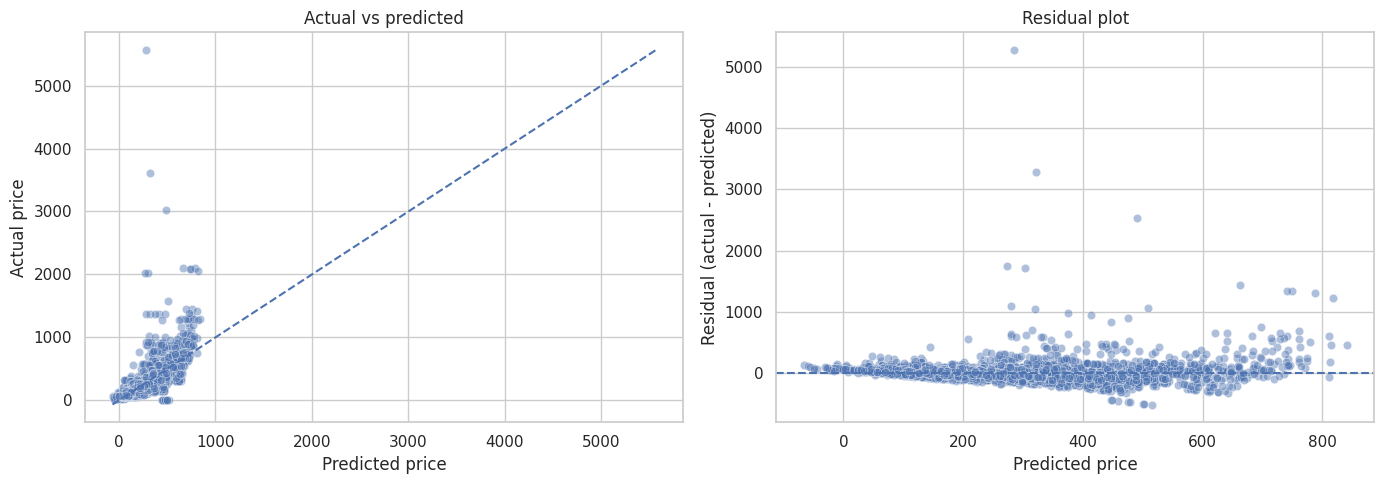

In [18]:
residuals = y_valid - ridge_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=ridge_pred, y=y_valid, alpha=0.45, ax=axes[0])
low = min(y_valid.min(), ridge_pred.min())
high = max(y_valid.max(), ridge_pred.max())
axes[0].plot([low, high], [low, high], linestyle="--")
axes[0].set_xlabel("Predicted price")
axes[0].set_ylabel("Actual price")
axes[0].set_title("Actual vs predicted")

sns.scatterplot(x=ridge_pred, y=residuals, alpha=0.45, ax=axes[1])
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Predicted price")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residual plot")
plt.tight_layout()
plt.show()

In [19]:
# Refit with every labeled row once model selection is complete.
best_model.fit(X, y)
test_predictions = best_model.predict(X_test)

# Prices should not be negative. Keep full precision internally; round for CSV readability.
test_predictions = np.clip(test_predictions, a_min=0, a_max=None)

# Use the provided template to preserve its row order and required IDs.
submission = sample_submission[["id"]].merge(
    pd.DataFrame({"id": test["id"], "price": test_predictions}),
    on="id",
    how="left",
    validate="one_to_one"
)

assert submission["price"].notna().all(), "Some test IDs did not receive predictions"
assert submission["id"].equals(sample_submission["id"]), "Submission row order/IDs changed"
assert list(submission.columns) == ["id", "price"]

submission["price"] = submission["price"].round(2)
submission.to_csv("submission_linear_regression.csv", index=False)

print("Saved submission_linear_regression.csv")
display(submission.head())
print("Submission shape:", submission.shape)
print(submission["price"].describe())

Saved submission_linear_regression.csv


,id,price
0,18395,65.56
1,11771,150.72
2,22326,541.60
3,18332,151.33
4,11021,367.25


Submission shape: (4520, 2)
count    4520.000000
mean      282.206852
std       156.117552
min         0.000000
25%       165.690000
50%       265.785000
75%       377.415000
max      1523.550000
Name: price, dtype: float64
